# 07 · Comportamiento mensual real — Berkeley

La fuente fue revisada antes de implementar. Ver docs/project_plan.md y docs/data_readiness.md. Subconjunto descriptivo de meses regulares; no reproduce toda la muestra del artículo. No se crean visitas diarias, targets o estados validados. El contrato final de Retention ya dispone de un target y benchmark propios; aquí solo se cotejan features, claves y fronteras.

In [1]:
from pathlib import Path
import sys,json
import pandas as pd
from IPython.display import display,Image
ROOT=Path.cwd()
if not (ROOT/"src").is_dir(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from src.data.berkeley import load_berkeley,monthly_observations
from src.features.monthly import monthly_metrics
source,labels=load_berkeley(ROOT/"data/raw/berkeley/data.zip")
audit=monthly_observations(source)
features=monthly_metrics(audit)
print("Origen real:",len(source),"filas;",source.id.nunique(),"IDs")
print("Meses regulares:",len(features),"de",features.member_id.nunique(),"miembros")
assert not features.synthetic.any()
assert audit.loc[~audit.attendance_eligible,"recorded_attendance_month"].isna().all()

Origen real: 491506 filas; 10241 IDs
Meses regulares: 84251 de 8073 miembros


In [2]:
display(pd.read_csv(ROOT/"data/processed/berkeley/selection_stages.csv"))
display(pd.read_csv(ROOT/"handoff/monthly_feature_catalog.csv"))
display(features.drop(columns="member_id").describe().T)
print((ROOT/"reports/berkeley/integration_readiness.json").read_text(encoding="utf-8"))

,stage,rows,members
0,All source calendar rows,491506,10241
1,Inside documented club span,450051,10241
2,Source review flags accepted,372809,8606
3,Regular contract months (1/2),84251,8073


,feature,definition,business_meaning,calculation_window,data_requirements,limitations,unit,status
0,dataset_id,berkeley_gym_aer_2006,Population namespace,Pinned source,Pinned source identity and explicit adapter me...,"Metadata/context, not an attendance state; sam...",identifier,implemented_monthly_research
1,member_id,str(int(source.id)),Shared identity inside this source only,Pinned source,Pinned source identity and explicit adapter me...,"Metadata/context, not an attendance state; sam...",identifier,implemented_monthly_research
2,period_end,Last calendar date of source.time month after ...,Monthly observation key,Current month,Pinned source identity and explicit adapter me...,"Metadata/context, not an attendance state; sam...",date,implemented_monthly_research
3,club_id,"source.club: 11,13,16",Source club context; not event-branch diversity,Current source row,Pinned source identity and explicit adapter me...,"Metadata/context, not an attendance state; sam...",identifier,implemented_monthly_research
4,as_of_exclusive,Midnight immediately following period_end,Explicit research calculation boundary,Month close,Pinned source identity and explicit adapter me...,"Metadata/context, not an attendance state; sam...",datetime,implemented_monthly_research
5,synthetic,False,Disclose real historical gym origin,Pinned source,Pinned source identity and explicit adapter me...,"Metadata/context, not an attendance state; sam...",boolean,implemented_monthly_research
6,selection_policy_id,berkeley_regular_month_v1,Trace conservative row eligibility,Current adapter version,Pinned source identity and explicit adapter me...,"Metadata/context, not an attendance state; sam...",identifier,implemented_monthly_research
7,availability_basis,assumed_month_close_no_ingestion_clock,Expose research availability assumption,Month close,Pinned source identity and explicit adapter me...,"Metadata/context, not an attendance state; sam...",categorical,implemented_monthly_research
8,coverage_basis,author_flags_and_documented_month_span,Expose coverage/eligibility evidence basis,Retrospective source audit,Pinned source identity and explicit adapter me...,"Metadata/context, not an attendance state; sam...",categorical,implemented_monthly_research
9,recorded_attendance_month,Source attend in the eligible calendar month,Recorded monthly attendance volume,Current calendar month,"Pinned Berkeley member/month identity, attend ...",Historical regular-month subset; no verified i...,events,implemented_monthly_research


,count,mean,min,25%,50%,75%,max,std
period_end,84251,1999-07-20 18:16:44.740596,1997-05-31 00:00:00,1998-11-30 00:00:00,1999-07-31 00:00:00,2000-03-31 00:00:00,2001-01-31 00:00:00,NaN
club_id,84251.0,12.639304,11.0,11.0,13.0,13.0,16.0,1.800995
as_of_exclusive,84251,1999-07-21 18:16:44.740596,1997-06-01 00:00:00,1998-12-01 00:00:00,1999-08-01 00:00:00,2000-04-01 00:00:00,2001-02-01 00:00:00,NaN
recorded_attendance_month,84251.0,4.716312,0.0,0.0,3.0,8.0,42.0,5.210645
attendance_previous_month,73352.0,4.948904,0.0,0.0,3.0,8.0,42.0,5.246719
attendance_change_vs_previous_month,73352.0,-0.3052,-31.0,-2.0,0.0,1.0,26.0,3.647945
attendance_pct_change_vs_previous_month,52865.0,0.067321,-1.0,-0.6,-0.153846,0.285714,26.0,1.2261
attendance_sum_3_calendar_months,64347.0,14.586383,0.0,2.0,11.0,23.0,103.0,14.274043
attendance_mean_3_calendar_months,64347.0,4.862128,0.0,0.666667,3.666667,7.666667,34.333333,4.758014
attendance_std_3_calendar_months,64347.0,1.662531,0.0,0.471405,1.414214,2.494438,14.290634,1.457381


{
  "dataset_id": "berkeley_gym_aer_2006",
  "table_sha256": "e56ffe6177eb5e1508555d07a756a58f9e74d051eed12601ab5a34919949289c",
  "local_archive_sha256": "f2abbaa0312b697c56892621782073a8dd4b0fbf7cdbb8b9746a28c6398772f9",
  "shared_retention_archive_sha256": "f2abbaa0312b697c56892621782073a8dd4b0fbf7cdbb8b9746a28c6398772f9",
  "archive_identity_matches": true,
  "source_key": [
    "id",
    "time"
  ],
  "canonical_key": [
    "dataset_id",
    "member_id",
    "period_end"
  ],
  "matching_behavior_keys_in_original_population": 84251,
  "behavior_rows": 84251,
  "retention_canonical_export_available": true,
  "verified_scope": "read-only canonical feature-key, current-count and boundary comparison; no outcomes/scores joined",
  "other_populations_joined": false,
  "checked_at": "2026-10-20",
  "retention_contract_version": "0.5.0",
  "retention_existing_target_version": "berkeley_clear_transition_v1",
  "retention_existing_historical_model": true,
  "retention_features_sha256": "fb8

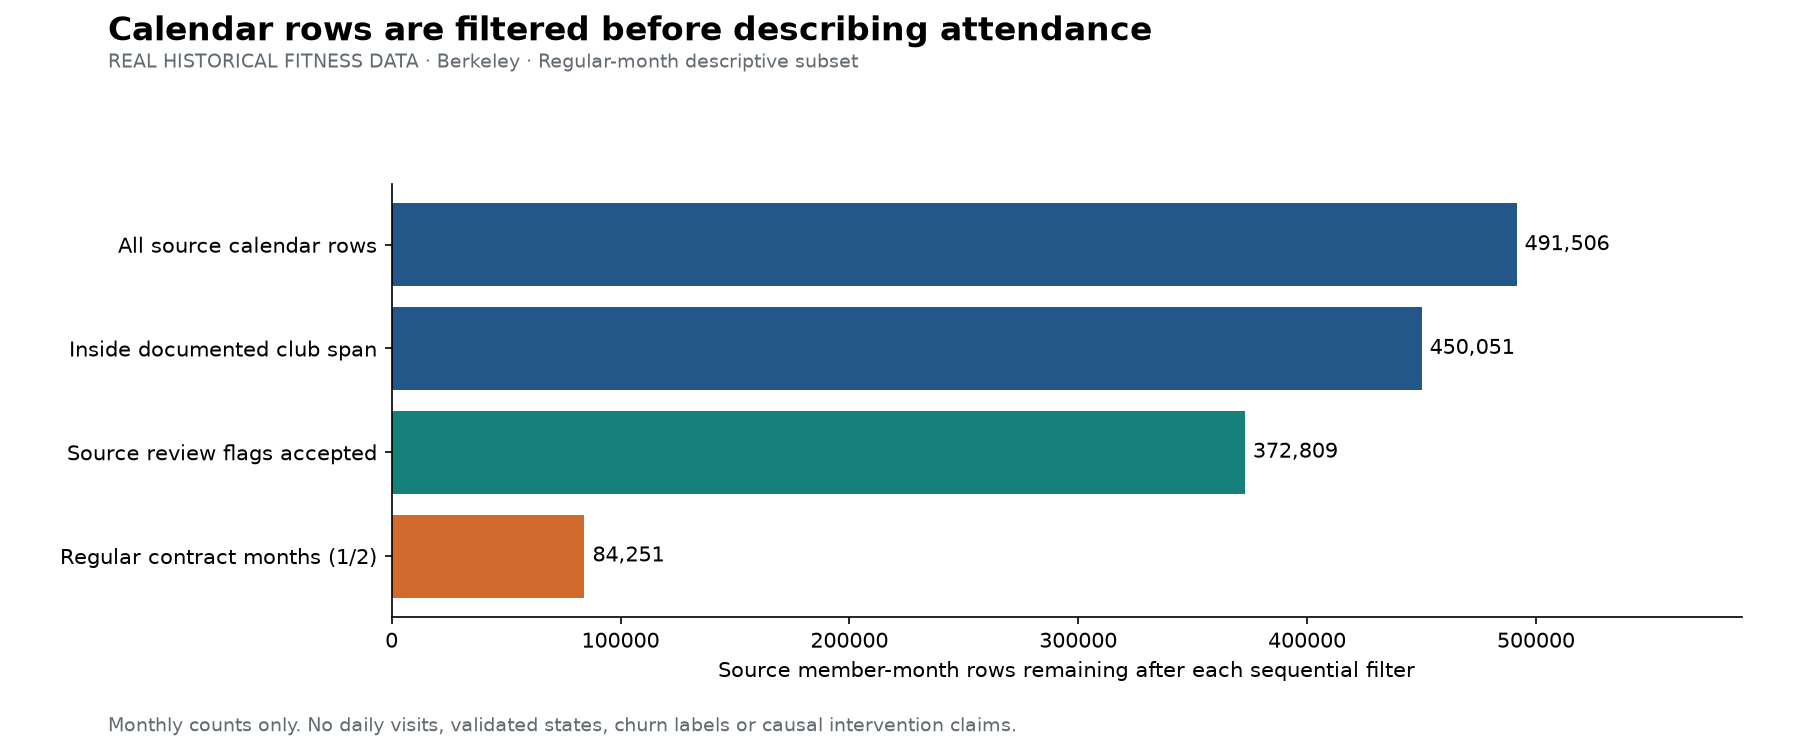

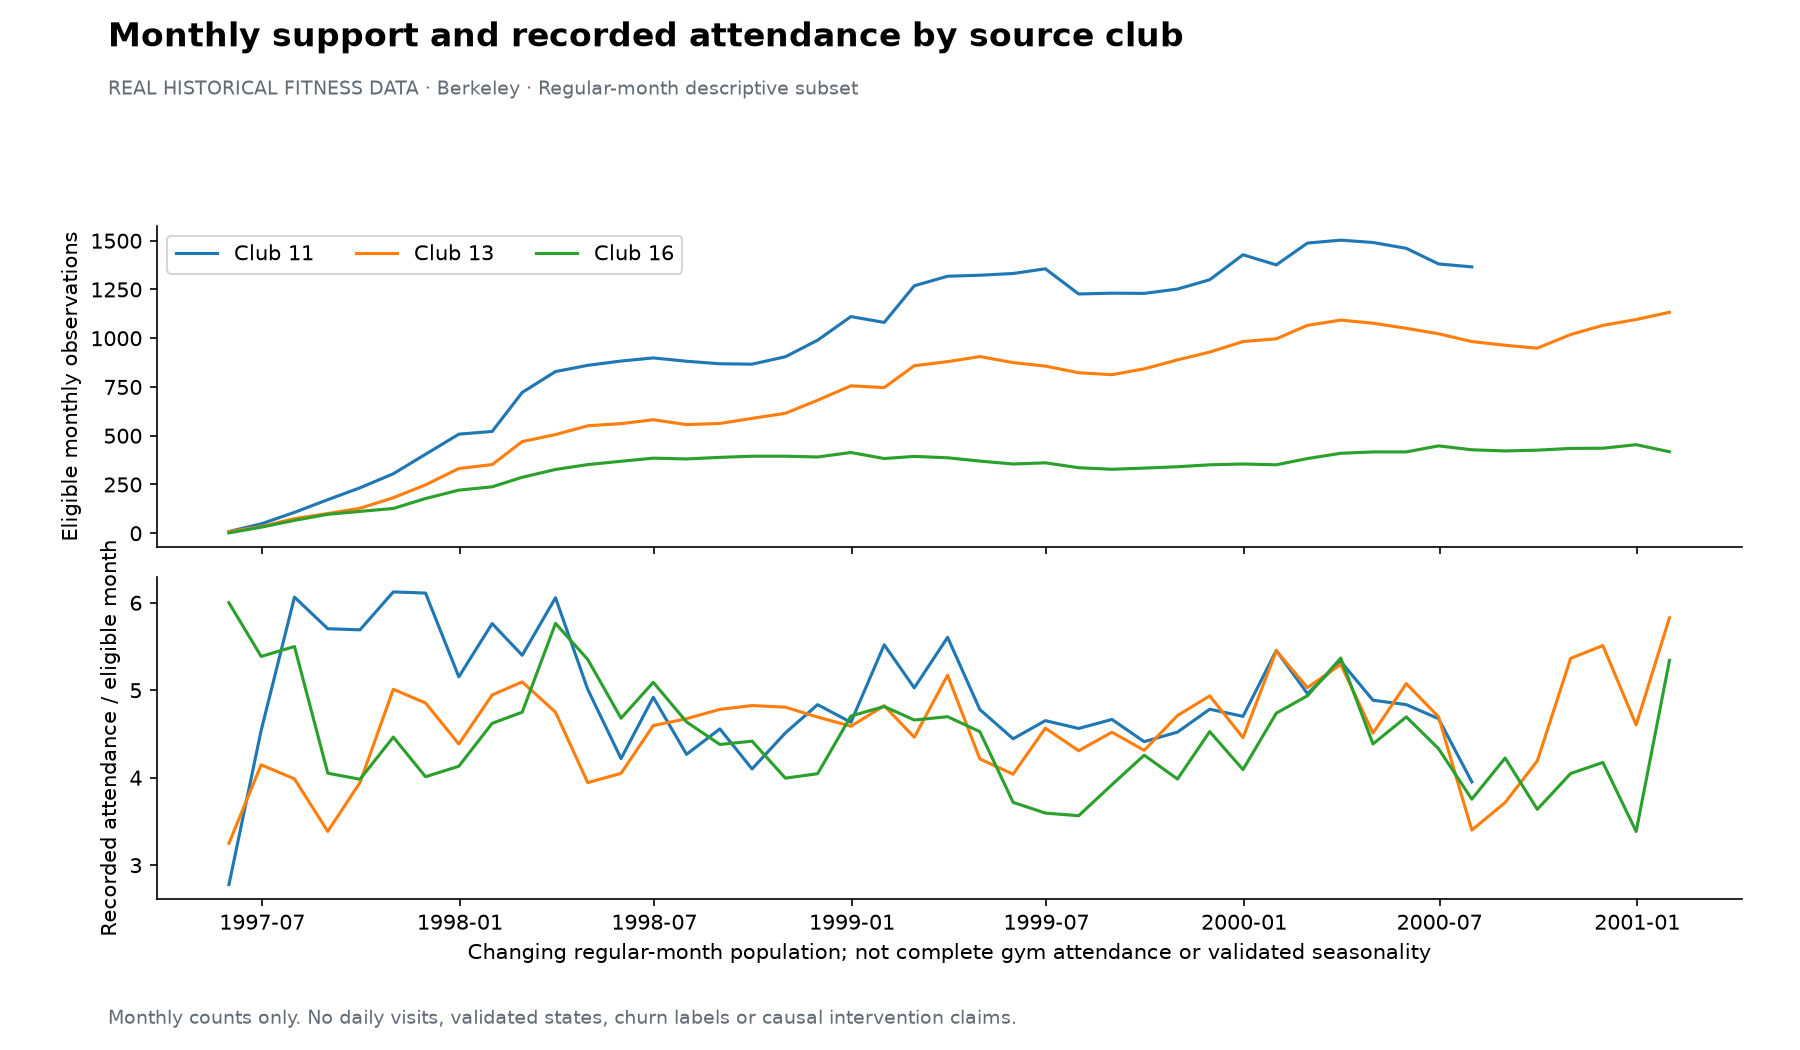

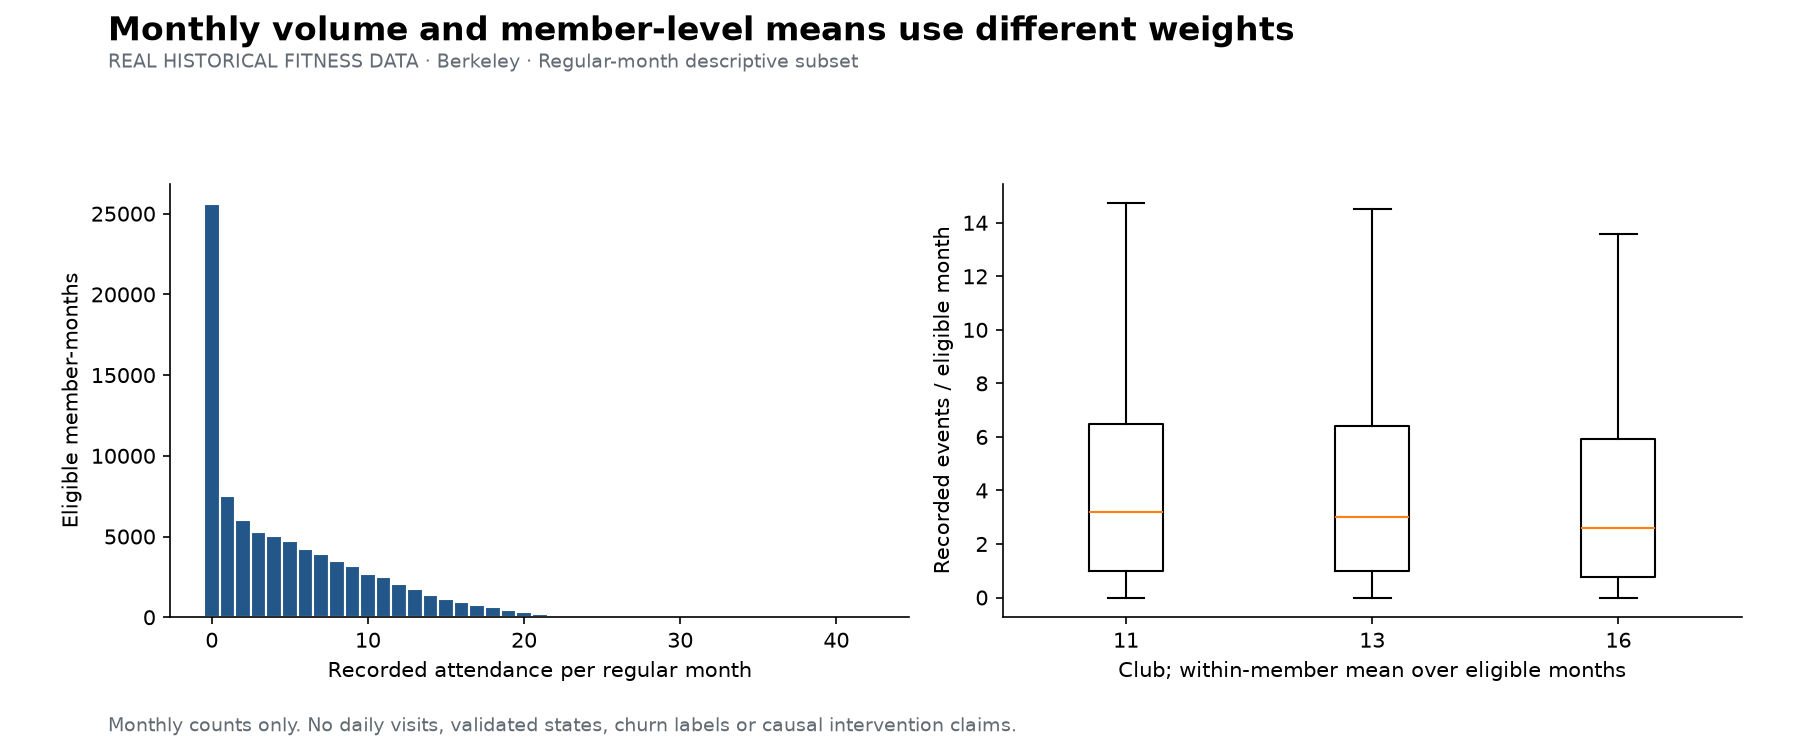

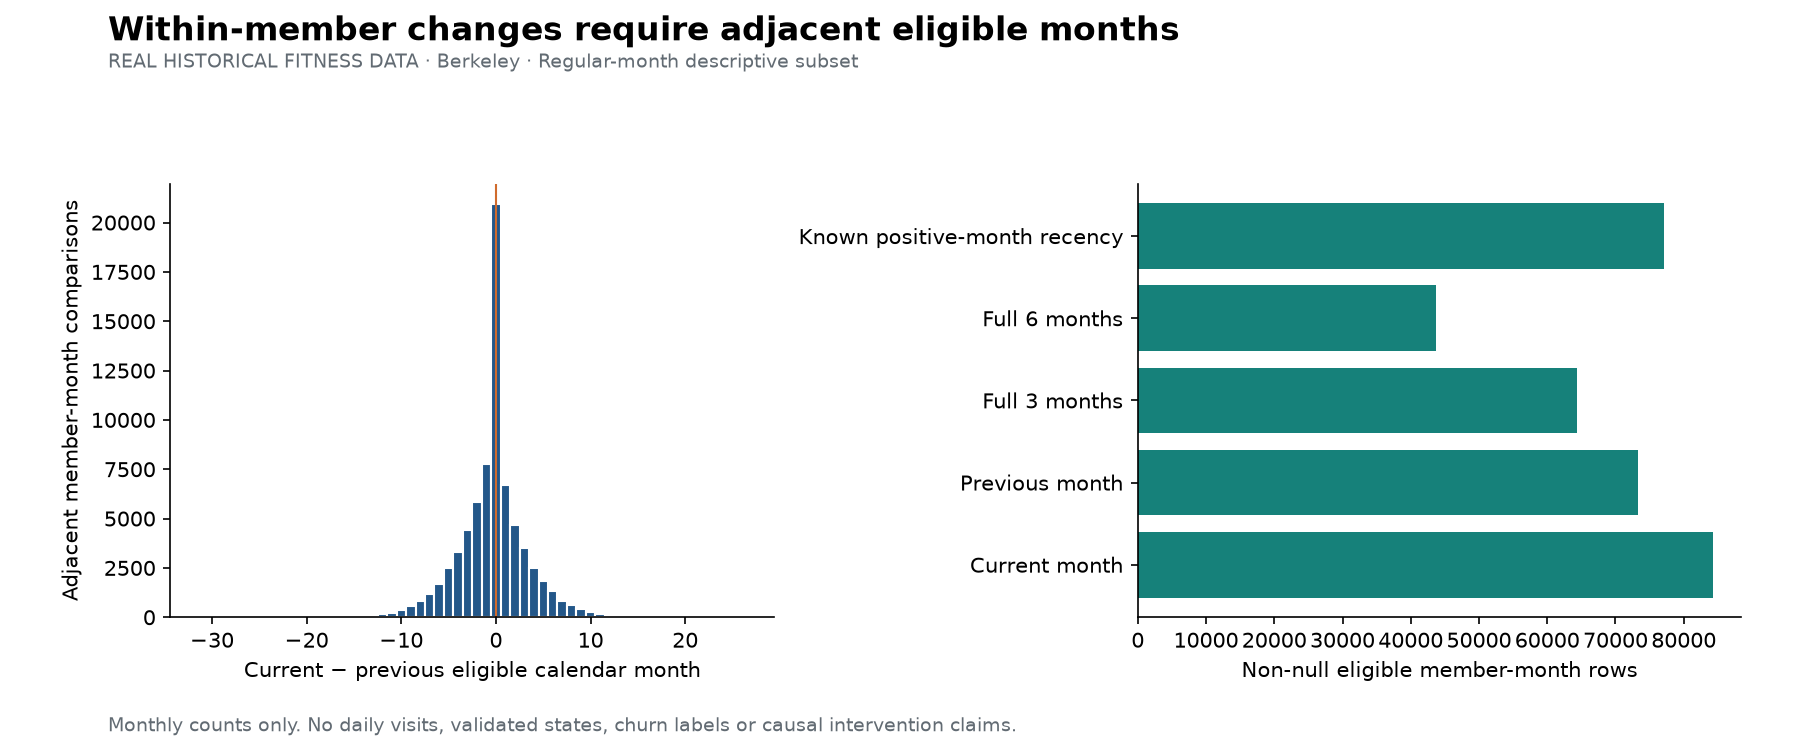

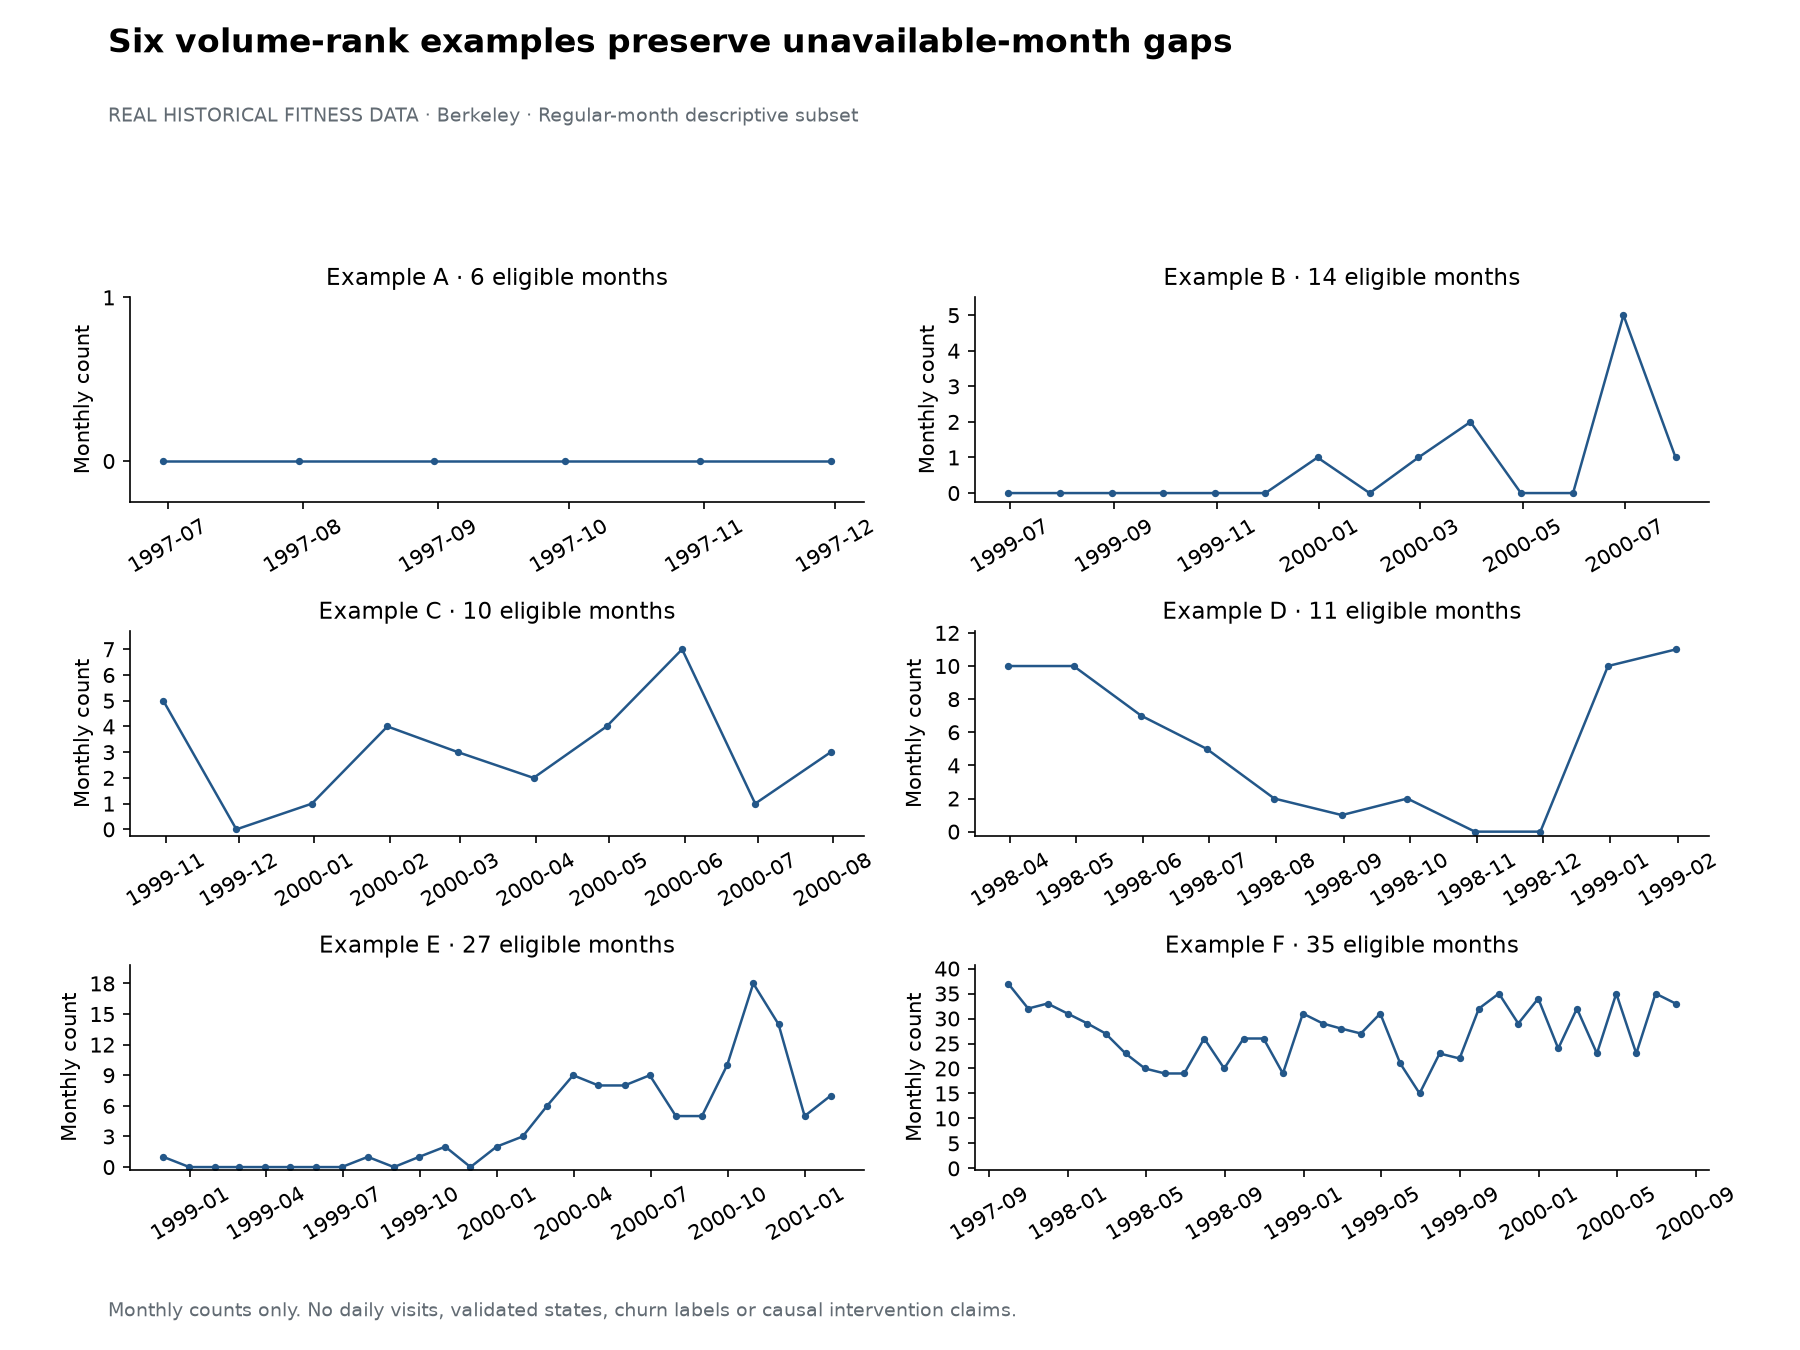

In [3]:
for path in sorted((ROOT/"reports/berkeley/figures").glob("*.png")):
    display(Image(filename=str(path)))

## Interpretación

Las ventanas requieren meses consecutivos elegibles. Los huecos no son ceros. Rachas y recencia mensual no son antigüedad ni recencia diaria. La compatibilidad con Retention coteja su export real de features y explica diferencias de selección/historial; no se importan sus outcomes ni scores y no se reemplazan features de su modelo. No se unen otras poblaciones. La disponibilidad al cierre mensual es una hipótesis sin reloj de ingesta; los resultados son históricos y descriptivos.